In [1]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# Задание 1. Чтение и отображение

- Прочитать изображение
- Отобразить каждый канал цвета
- Отобразить гистограмму яркостей каждого канала
- Отобразить изображение

In [2]:
path1 = '../data/Lenna_(test_image).png'
img1 = np.array(Image.open(path1))

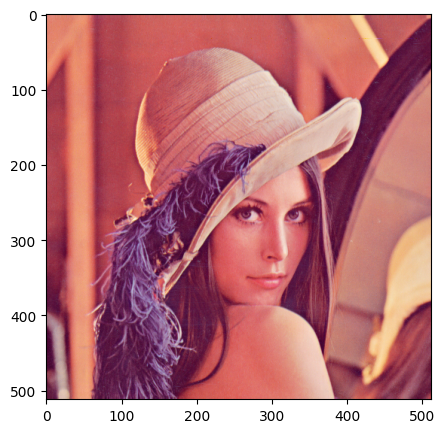

In [3]:
w, h = 10, 5
fig, axes = plt.subplots(figsize=(w, h))
axes.imshow(img1)
plt.show()

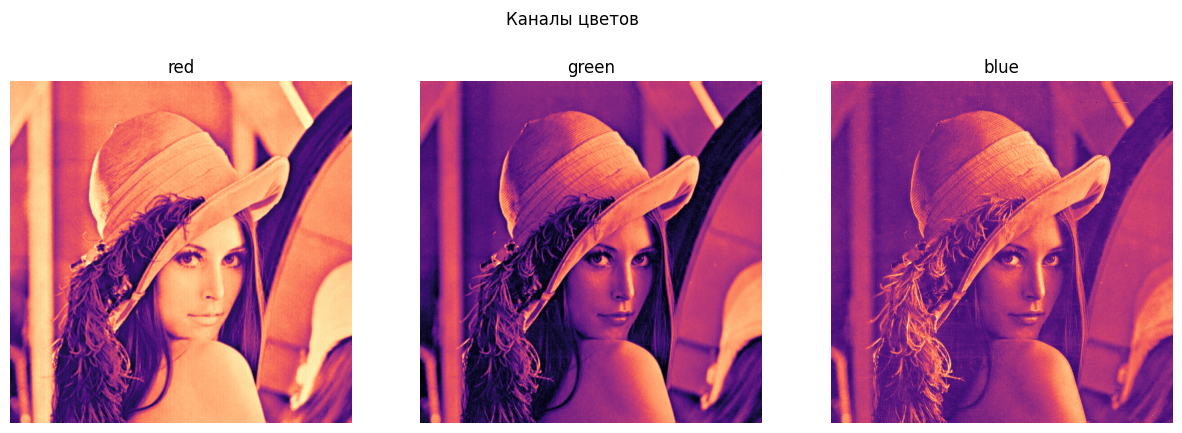

In [4]:
w, h = 15, 5
fig, axes = plt.subplots(1, 3, figsize=(w, h))
fig.suptitle('Каналы цветов')

colors = ['red', 'green', 'blue']
for i in range(3):
    axes[i].imshow(img1[:, :, i], cmap='magma')
    axes[i].set_title(colors[i])
    axes[i].axis('off')

plt.show()

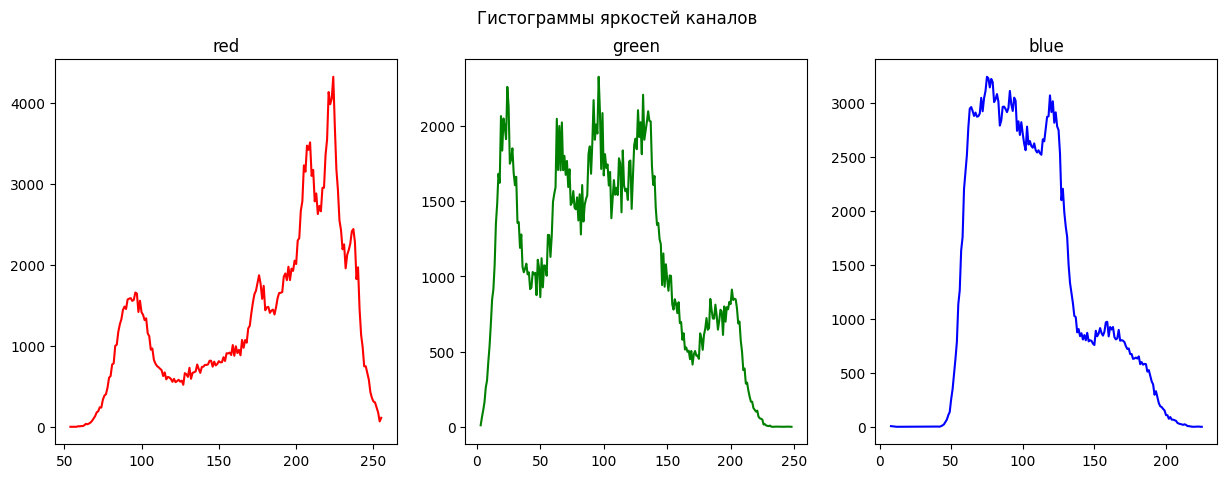

In [5]:
colors = ['red', 'green', 'blue']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Гистограммы яркостей каналов')

for i in range(3):
    values, counts = np.unique(img1[:, :, i], return_counts=True)
    axes[i].plot(values, counts, color=colors[i])
    axes[i].set_title(colors[i])

# Задание 2. Добавление границы

In [6]:
def add_zero_border(image, border_size):
    bordered_img = image.transpose(2, 0, 1)
    _, w, h = bordered_img.shape
    
    bordered_img = np.insert(bordered_img, [0] * border_size, 0, 2)
    bordered_img = np.insert(bordered_img, [h + border_size] * border_size, 0, 2)

    bordered_img = np.insert(bordered_img, [0] * border_size, 0, 1)
    bordered_img = np.insert(bordered_img, [w + border_size] * border_size, 0, 1)

    bordered_img = bordered_img.transpose(1, 2, 0)
    
    return bordered_img

In [7]:
def add_clamp_border(image, border_size):
    bordered_img = add_zero_border(image, border_size)
    bordered_img = bordered_img.transpose(2, 0, 1)

    top_border = bordered_img[:, border_size, border_size : bordered_img.shape[2] - border_size]
    bot_border = bordered_img[:, bordered_img.shape[1] - border_size - 1, border_size : bordered_img.shape[2] - border_size]

    left_border = bordered_img[:, border_size : bordered_img.shape[1] - border_size, border_size]
    right_border = bordered_img[:, border_size : bordered_img.shape[1] - border_size, bordered_img.shape[2] - border_size - 1]

    top_border = np.expand_dims(top_border, axis=1)
    top_border = np.repeat(top_border, border_size, 1)
    bordered_img[:, : border_size, border_size : bordered_img.shape[2] - border_size] = top_border
    
    bot_border = np.expand_dims(bot_border, axis=1)
    bot_border = np.repeat(bot_border, border_size, 1)
    bordered_img[:, bordered_img.shape[1] - border_size : , border_size : bordered_img.shape[2] - border_size] = bot_border

    left_border = np.expand_dims(left_border, axis=1)
    left_border = np.repeat(left_border, border_size, 1)
    bordered_img[:, border_size : bordered_img.shape[1] - border_size, :border_size] = left_border.transpose(0, 2, 1)

    right_border = np.expand_dims(right_border, axis=1)
    right_border = np.repeat(right_border, border_size, 1)
    bordered_img[:, border_size : bordered_img.shape[1] - border_size, bordered_img.shape[2] - border_size:] = right_border.transpose(0, 2, 1)

    top_left_corner = bordered_img[:, border_size, border_size]
    top_left_corner = np.expand_dims(top_left_corner, (1, 2))
    top_left_corner = np.repeat(top_left_corner, border_size, 2)
    top_left_corner = np.repeat(top_left_corner, border_size, 1)
    bordered_img[:, :border_size, :border_size] = top_left_corner

    top_right_corner = bordered_img[:, border_size, bordered_img.shape[2] - border_size]
    top_right_corner = np.expand_dims(top_right_corner, (1, 2))
    top_right_corner = np.repeat(top_right_corner, border_size, 2)
    top_right_corner = np.repeat(top_right_corner, border_size, 1)
    bordered_img[:, :border_size, bordered_img.shape[2] - border_size :] = top_right_corner

    bot_right_corner = bordered_img[:, bordered_img.shape[1] - border_size - 1, bordered_img.shape[2] - border_size - 1]
    bot_right_corner = np.expand_dims(bot_right_corner, (1, 2))
    bot_right_corner = np.repeat(bot_right_corner, border_size, 2)
    bot_right_corner = np.repeat(bot_right_corner, border_size, 1)
    bordered_img[:, bordered_img.shape[1] - border_size:, bordered_img.shape[2] - border_size :] = bot_right_corner

    bot_left_corner = bordered_img[:, bordered_img.shape[1] - border_size - 1, border_size]
    bot_left_corner = np.expand_dims(bot_left_corner, (1, 2))
    bot_left_corner = np.repeat(bot_left_corner, border_size, 2)
    bot_left_corner = np.repeat(bot_left_corner, border_size, 1)
    bordered_img[:, bordered_img.shape[1] - border_size:, :border_size] = bot_left_corner

    
    bordered_img = bordered_img.transpose(1, 2, 0)
    return bordered_img

In [8]:
def add_mirror_border(image, border_size):
    bordered_img = add_zero_border(image, border_size)
    bordered_img = bordered_img.transpose(2, 0, 1)

    top_border = bordered_img[:, border_size:2*border_size, border_size : bordered_img.shape[2] - border_size]
    top_border = np.flip(top_border, axis=1)
    bordered_img[:, : border_size, border_size : bordered_img.shape[2] - border_size] = top_border
    
    bot_border = bordered_img[:, bordered_img.shape[1] - 2*border_size - 1 : bordered_img.shape[1] - border_size - 1, border_size : bordered_img.shape[2] - border_size]
    bot_border = np.flip(bot_border, axis=1)
    bordered_img[:, bordered_img.shape[1] - border_size : , border_size : bordered_img.shape[2] - border_size] = bot_border
    
    left_border = bordered_img[:, border_size : bordered_img.shape[1] - border_size, border_size:2*border_size]
    left_border = np.flip(left_border, axis=2)
    bordered_img[:, border_size : bordered_img.shape[1] - border_size, :border_size] = left_border
    
    right_border = bordered_img[:, border_size : bordered_img.shape[1] - border_size, bordered_img.shape[2] - 2*border_size - 1 : bordered_img.shape[2] - border_size - 1]
    right_border = np.flip(right_border, axis=2)
    bordered_img[:, border_size : bordered_img.shape[1] - border_size, bordered_img.shape[2] - border_size:] = right_border

    top_left_corner = bordered_img[:, border_size:2*border_size, border_size:2*border_size]
    top_left_corner = top_left_corner.transpose((0, 2, 1))
    top_left_corner = np.flip(top_left_corner, axis=2)
    top_left_corner = np.flip(top_left_corner, axis=1)
    bordered_img[:, :border_size, :border_size] = top_left_corner

    top_right_corner = bordered_img[:, border_size:2*border_size, bordered_img.shape[2] - 2*border_size : bordered_img.shape[2] - border_size]
    top_right_corner.transpose((0, 2, 1))
    top_right_corner = np.flip(top_right_corner, axis=1)
    bordered_img[:, :border_size, bordered_img.shape[2] - border_size :] = top_right_corner
    

    bot_right_corner = bordered_img[:, bordered_img.shape[1] - 2*border_size - 1 : bordered_img.shape[1] - border_size - 1, bordered_img.shape[2] - 2*border_size - 1: bordered_img.shape[2] - border_size - 1]
    bot_right_corner = bot_right_corner.transpose((0, 2, 1))
    bot_right_corner = np.flip(bot_right_corner, axis=2)
    bot_right_corner = np.flip(bot_right_corner, axis=1)
    bordered_img[:, bordered_img.shape[1] - border_size:, bordered_img.shape[2] - border_size :] = bot_right_corner


    
    bot_left_corner = bordered_img[:, bordered_img.shape[1] - 2*border_size - 1 : bordered_img.shape[1] - border_size - 1, border_size:2*border_size]
    bot_left_corner = bot_left_corner.transpose((0, 2, 1))
    bordered_img[:, bordered_img.shape[1] - border_size:, :border_size] = bot_left_corner

    
    bordered_img = bordered_img.transpose(1, 2, 0)
    return bordered_img

In [9]:
def add_border(image, border_size, method):
    if method == 'zero':
        proccessed_img = add_zero_border(image, border_size)
    elif method == 'clamp':
        proccessed_img = add_clamp_border(image, border_size)
    elif method == 'mirror':
        proccessed_img = add_mirror_border(image, border_size)
        
    return proccessed_img

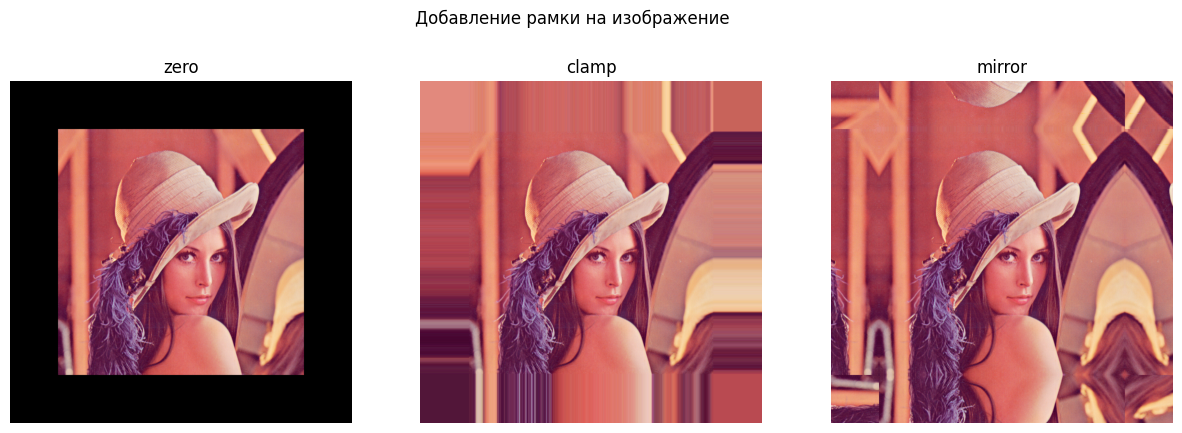

In [10]:
border_size = 100

modes = ['zero', 'clamp', 'mirror']
edited_imgs = [add_border(img1, border_size, mode) for mode in modes]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Добавление рамки на изображение')

for i in range(3):
    axes[i].imshow(edited_imgs[i])
    axes[i].set_title(modes[i])
    axes[i].axis('off')

plt.show()

# Задание 3. RGB -> GRAY

In [11]:
def simple_gray(img):
    gray = img.copy().transpose(2, 0, 1)
    r, g, b = gray
    r = (r / 3)
    g = (g / 3)
    b = (b / 3)
    gray = (r + g + b).astype('uint8')

    return gray

In [12]:
def weighted_gray(img):
    gray = img.copy().transpose(2, 0, 1)
    r, g, b = gray
    r = (0.299 * r)
    g = (0.587 * g)
    b = (0.114 * b)
    gray = (r + g + b).astype('uint8')

    return gray

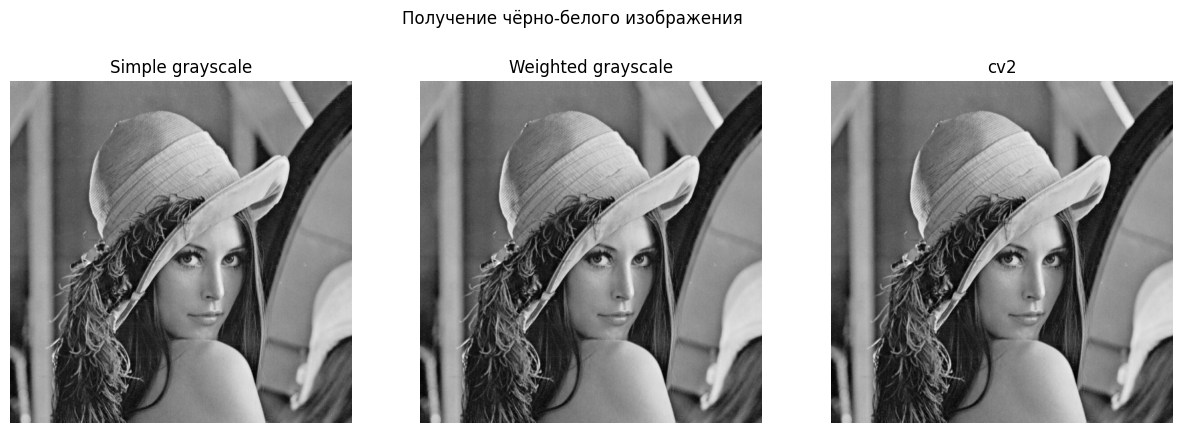

In [13]:
simple_gray_img = simple_gray(img1)
weighted_gray_img = weighted_gray(img1)
cv_gray_img = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray_imgs = [simple_gray_img, weighted_gray_img, cv_gray_img]
titles = ['Simple grayscale', 'Weighted grayscale', 'cv2']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Получение чёрно-белого изображения')

for i in range(3):
    axes[i].imshow(gray_imgs[i], cmap='gray')
    axes[i].set_title(titles[i])
    axes[i].axis('off')
    
plt.show()

# Задание 4. Манипуляция с пикселями

In [14]:
def shift_image(image, channel, val):
    img = image.copy().transpose(2, 0, 1)
    r, g, b = img

    if channel == 'r':
        selected = r
        other = [g, b]
    elif channel == 'g':
        selected = g
        other = [r, b]
    elif channel == 'b':
        selected = b
        other = [r, g]

    selected = selected.astype('float32')
    
    selected_scaled = selected * val
    selected_scaled = selected_scaled * 255 / (selected_scaled.max() - selected_scaled.min())
    selected_scaled = selected_scaled.astype('uint8')

    if channel == 'r':
        res = np.array([selected_scaled, *other])
    elif channel == 'g':
        res = np.array([other[0], selected_scaled, other[1]])
    elif channel == 'b':
        res = np.array([*other, selected_scaled])

    res = res.transpose(1, 2, 0)
    return res

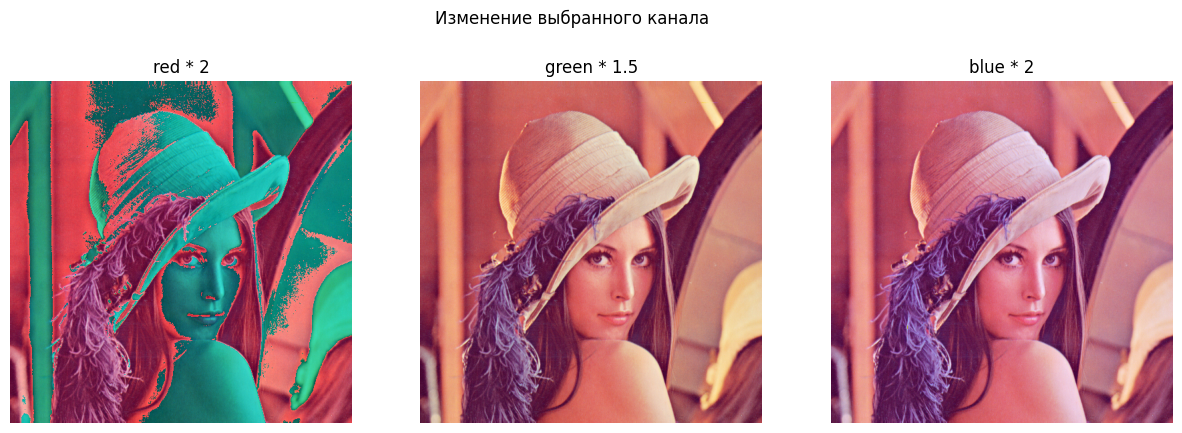

In [15]:
r_coef = 2
g_coef = 1.5
b_coef = 2

edited_img1 = shift_image(img1, 'r', r_coef)
edited_img2 = shift_image(img1, 'g', g_coef)
edited_img3 = shift_image(img1, 'b', b_coef)
edited_imgs = [edited_img1, edited_img2, edited_img3]
edited_imgs = [shift_image(img1, x[0], x[1]) for x in zip('rgb', [r_coef, g_coef, b_coef])]
titles = [f'red * {r_coef}', f'green * {g_coef}', f'blue * {b_coef}']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Изменение выбранного канала')

for i in range(3):
    axes[i].imshow(edited_imgs[i])
    axes[i].set_title(titles[i])
    axes[i].axis('off')

plt.show()

In [16]:
def get_rect(image, rect_coord, color, val):
    img = image.copy().transpose(2, 0, 1)
    x1, y1 = rect_coord[0]
    x2, y2 = rect_coord[1]
    
    rect = img[:, x1:x2+1, y1:y2+1].copy()
    rect = rect.transpose(1, 2, 0)
    edited_rect = shift_image(rect, color, val)
    edited_rect = edited_rect.transpose(2, 0, 1)

    img[:, x1:x2+1, y1:y2+1] = edited_rect
    img = img.transpose(1, 2, 0)
    
    return (img, rect)

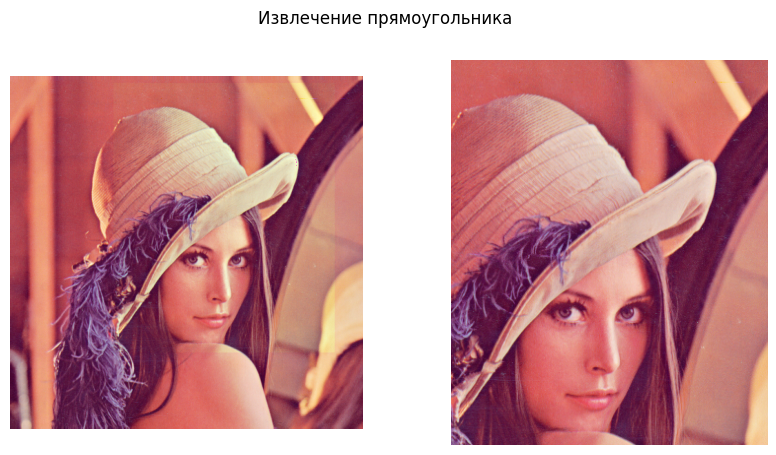

In [17]:
coords = [(10, 150), (400, 470)]
color = 'g'
val = 0.4
edited_img, rect = get_rect(img1, coords, color, val)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('Извлечение прямоугольника')

axes[0].imshow(edited_img)
axes[0].axis('off')

axes[1].imshow(rect)
axes[1].axis('off')

plt.show()

# Задание 5. RGB <-> HSV

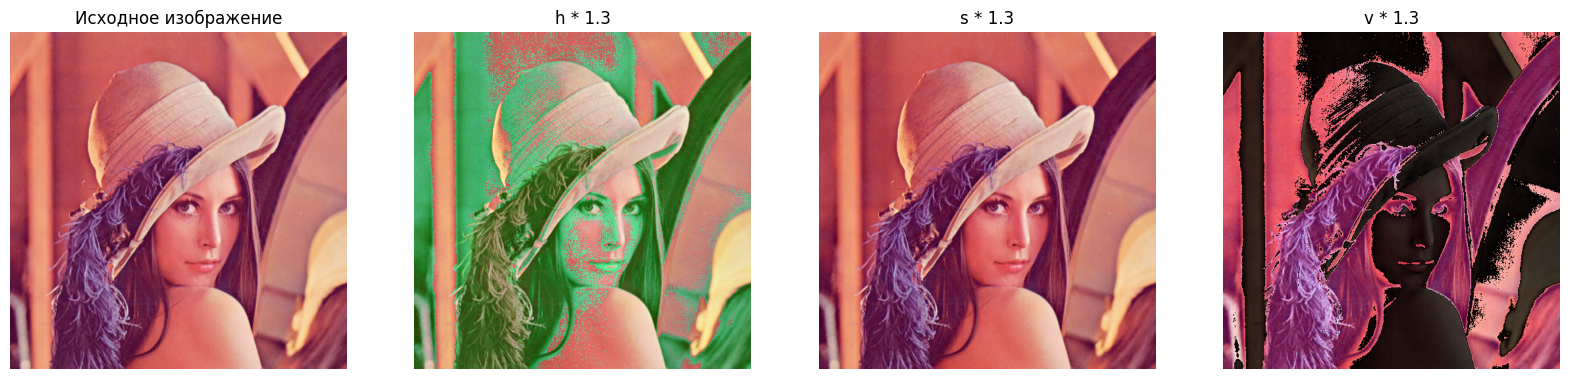

In [23]:
hsv_img = cv2.cvtColor(img1, cv2.COLOR_RGB2HSV)
hsv_shift_imgs = [shift_image(hsv_img, color, 1.3) for color in ['r', 'g', 'b']]

imgs = [img1] + [cv2.cvtColor(x, cv2.COLOR_HSV2RGB) for x in hsv_shift_imgs]
titles = ['Исходное изображение', 'h * 1.3', 's * 1.3', 'v * 1.3']

fig, axes = plt.subplots(1, len(imgs), figsize=(20, 5))
for i in range(len(imgs)):
    axes[i].imshow(imgs[i])
    axes[i].set_title(titles[i])
    axes[i].axis('off')

plt.show()